# Auto and cross power spectra with line-of-sight selection in FolpsD

This notebook shows how to compute, with the public FolpsD API,

* the **single-tracer (auto)** multipoles $P_\ell^{AA}$ and $P_\ell^{BB}$, and
* the **two-tracer (cross)** multipoles $P_\ell^{AB}$,

for two tracers that each have their **own** line-of-sight (LOS) selection. Think of the blue (B)
and red (R) halves of a colour-split sample: they share the matter and velocity fields but have
different biases and different selection amplitudes.

Four models are shown, from simplest to most complete:

| Model | Selection | How to call it |
|---|---|---|
| **M0** | none | `get_rsd_pkell(...)` |
| **M1** | Kaiser-only anisotropic bias $A$: $Z_1 = b_1 + f\mu^2 + A(\mu^2 - 1/3)$, loops unchanged | `get_rsd_pkmu(..., bA=...)` |
| **M2** | full one-loop model, linear selection only: $b_1 \to b_1 - A/3$, $s_\eta = -A/f$ | `get_rsd_pkell(..., selection=SelectionBias(s_eta=...))` |
| **M3** | full one-loop model with all nine selection coordinates | `get_rsd_pkell(..., selection=SelectionBias(...))` |

For a cross spectrum, tracer A is given by `pars` / `selection` and tracer B by `pars_b` / `selection_b`,
plus a pair-level `cross_nuisance` vector for the cross counterterms and noise.

The physics behind the selection model is explained in `selection_1loop_tutorial.ipynb` and
`docs/selection_1loop_equations.md`. The plain (unselected) cross spectrum is introduced in
`example_cross_power_numpy.ipynb`.

**Requirements:** EdS kernels, `model="EFT"` (no FoG damping, GTNS kept), branch `feature/selection-1loop-eds`.

## 1. Setup

FolpsD fixes its array backend at import time, so the backend is set before importing it.

In [1]:
import os, sys, time
from pathlib import Path

os.environ["FOLPS_BACKEND"] = "numpy"          # must be set before importing folps

def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "folps" / "__init__.py").exists() and (candidate / "folps" / "inputpkT.txt").exists():
            return candidate
    raise FileNotFoundError("FolpsD repository root not found from the current directory")

REPO = Path(os.environ["FOLPS_REPO_ROOT"]) if "FOLPS_REPO_ROOT" in os.environ else find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import eval_legendre
%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

from folps import (MatrixCalculator, NonLinearPowerSpectrumCalculator, RSDMultipolesPowerSpectrumCalculator,
                   SelectionBias, EFTExtension, build_selection_tables, tree_bA_to_linear_djs)

✅ Using NumPy with CPU.


/global/homes/a/aaviles/.local/lib/python3.12/site-packages/triumvirate/winconv.py:81: UserWarning: The `triumvirate.winconv` module is currently experimental. Its behaviour has not been fully tested and may change in the future.
  warnings.warn(


## 2. Loop tables and selection templates

These steps depend only on the cosmology, not on biases, counterterms or selection:

1. `MatrixCalculator` builds the cosmology-independent FFTLog matrices.
2. `calculate_loop_table` builds the full and no-wiggle (`table_now`) loop tables. Selection needs **EdS** kernels.
3. `build_selection_tables` builds the selection templates from the same calculator call.

The **same** tables serve the autos and the cross: the two-tracer contractions are assembled from them at evaluation time.

In [2]:
k_in, pk_in = np.loadtxt(REPO / "folps" / "inputpkT.txt", unpack=True)   # linear P(k) shipped with FolpsD
cosmo = dict(z=0.3, h=0.6711, Omega_m=0.3211636237981114, f0=0.6880638641959066, fnu=0.004453689063655854)

t0 = time.perf_counter()
matrices = MatrixCalculator(A_full=True, use_TNS_model=False).get_mmatrices()
nonlinear = NonLinearPowerSpectrumCalculator(mmatrices=matrices, kernels="EdS", **cosmo)
table, table_now = nonlinear.calculate_loop_table(k=k_in, pklin=pk_in, cosmo=None, **cosmo)
sel_tables = build_selection_tables(nonlinear)
f0 = float(table[-1])
print(f"tables built in {time.perf_counter() - t0:.1f} s;  f0 = {f0:.4f}")

calc = RSDMultipolesPowerSpectrumCalculator(model="EFT")
calc._printed_model_damping_pk = True       # silence the one-time 'EFT ignores damping' notice

Calculating matrices (no save path specified)


tables built in 14.3 s;  f0 = 0.6881


## 3. Parameters

Each tracer has a 12-entry parameter vector, here in the `bias_scheme="folps"` basis:

| Index | Name | Meaning |
|---:|---|---|
| 0–3 | `b1, b2, bs2, b3nl` | biases of this tracer |
| 4–6 | `alpha0, alpha2, alpha4` | counterterms (used by its auto spectrum) |
| 7 | `ctilde` | higher-order counterterm |
| 8–9 | `alphashot0, alphashot2` | stochastic amplitudes |
| 10 | `PshotP` | stochastic normalisation ($1/\bar n$) |
| 11 | `X_FoG_p` | FoG parameter (ignored by `model="EFT"`) |

The cross spectrum takes the biases (entries 0–3) from each tracer. Its counterterms and noise come from
`cross_nuisance` = entries 4–11 for the **pair**: `[alpha0, alpha2, alpha4, ctilde, alphashot0, alphashot2, PshotP, X_FoG_p]`.

The values below are illustrative, not best fits.

In [3]:
def coevo(b1):
    """bs2, b3nl from local Lagrangian coevolution."""
    return -4.0 / 7.0 * (b1 - 1.0), 32.0 / 315.0 * (b1 - 1.0)

PshotP = 1.0 / 2.1e-4          # same 1/nbar for both halves

b1_B, b1_R = 1.85, 2.15        # blue (B) and red (R) tracer
pars_B = [b1_B, 0.10, *coevo(b1_B), 2.0, -10.0, 1.0, 0.0, 0.05, -2.0, PshotP, 0.0]
pars_R = [b1_R, 0.50, *coevo(b1_R), 4.0, -16.0, 2.0, 0.0, 0.10, -4.0, PshotP, 0.0]
cross_BR = [3.0, -13.0, 1.5, 0.0, 0.0, -3.0, PshotP, 0.0]   # pair-level counterterms and noise

kobs = np.linspace(0.02, 0.20, 46)
qpar, qper = 1.0, 1.0          # AP parameters (set != 1 to include AP distortions)
ells = (0, 2, 4)
common = dict(kobs=kobs, qpar=qpar, qper=qper, table=table, table_now=table_now, damping=None, ells=ells)

## 4. M0: no selection

**Auto:** pass one parameter vector.

**Cross:** add `pars_b` and `cross_nuisance`. Swapping the tracers gives the same cross ($P^{BR} = P^{RB}$).

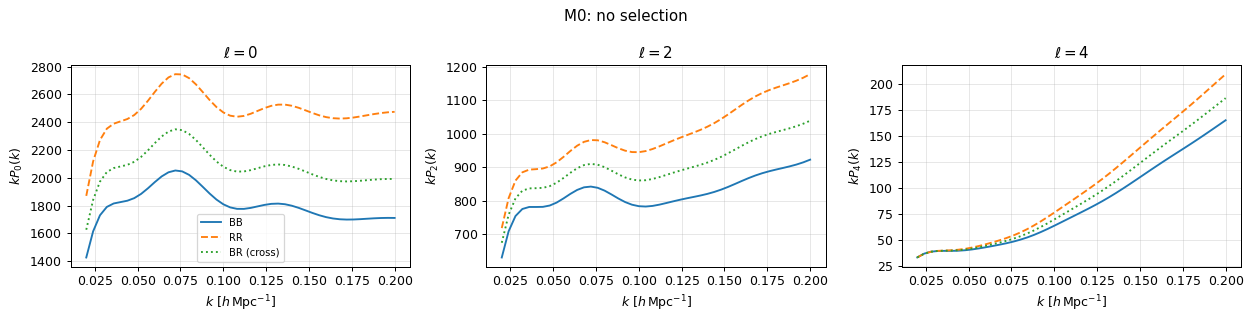

In [4]:
P0_BB = calc.get_rsd_pkell(pars=pars_B, **common)
P0_RR = calc.get_rsd_pkell(pars=pars_R, **common)
P0_BR = calc.get_rsd_pkell(pars=pars_B, pars_b=pars_R, cross_nuisance=cross_BR, **common)

def plot_spectra(spectra, title):
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
    for i, l in enumerate(ells):
        for (label, P), ls in zip(spectra.items(), ("-", "--", ":", "-.")):
            axs[i].plot(kobs, kobs * P[i], ls, label=label)
        axs[i].set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=fr"$k P_{l}(k)$", title=fr"$\ell={l}$")
    axs[0].legend(fontsize=8); fig.suptitle(title); fig.tight_layout(); plt.show()

plot_spectra({"BB": P0_BB, "RR": P0_RR, "BR (cross)": P0_BR}, "M0: no selection")

## 5. M1: Kaiser-only anisotropic bias $A$

The legacy `bA` argument adds $A_X(\mu^2 - 1/3)$ to the **tree-level** kernel of tracer $X$ only; the loops are unchanged.

* **Auto:** pass a single value, `bA=A`.
* **Cross:** pass `bA=(A_A, A_B)`. The tree then contains the mixed $A_A A_B (\mu^2-1/3)^2$ term, not $((A_A+A_B)/2)^2$.

`bA` is an argument of `get_rsd_pkmu` (it is not exposed by `get_rsd_pkell`), so we project $P(k,\mu)$ onto
multipoles ourselves. The helper below uses Gauss–Legendre quadrature without AP ($q_\parallel = q_\perp = 1$).
It is checked against `get_rsd_pkell` on the M0 spectra.

In [5]:
def pkell_from_pkmu(pkmu, nmu=6):
    """Even multipoles of P(k, mu) = pkmu(k[:, None], mu[None, :]) by Gauss-Legendre on mu in [0, 1] (no AP)."""
    x, w = np.polynomial.legendre.leggauss(2 * nmu)
    x, w = x[nmu:], w[nmu:]                     # P(k, mu) is even in mu
    p = pkmu(kobs[:, None], x[None, :])
    return np.array([(2 * l + 1) * np.sum(p * w * eval_legendre(l, x), axis=-1) for l in ells])

def pkmu_call(pars, **kw):
    return lambda k, mu: calc.get_rsd_pkmu(k, mu, pars, table, table_now, damping=None, **kw)

# check the helper on M0 (auto and cross)
for name, P, kw in (("BB", P0_BB, {}), ("BR", P0_BR, dict(pars_b=pars_R, cross_nuisance=cross_BR))):
    rel = np.max(np.abs(pkell_from_pkmu(pkmu_call(pars_B, **kw)) - P)) / np.max(np.abs(P))
    print(f"helper vs get_rsd_pkell, {name}: max rel. diff = {rel:.1e}")
    assert rel < 1e-8

helper vs get_rsd_pkell, BB: max rel. diff = 2.4e-16
helper vs get_rsd_pkell, BR: max rel. diff = 1.9e-16


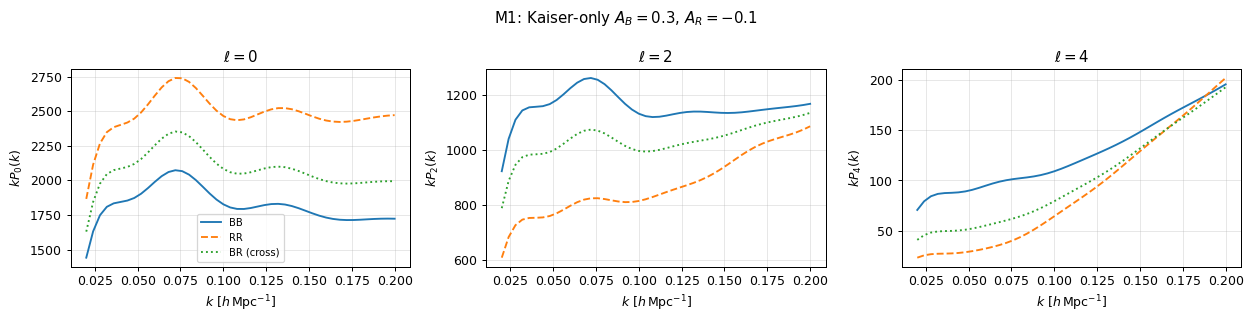

In [6]:
A_B, A_R = 0.30, -0.10           # independent Kaiser amplitudes of the two halves

P1_BB = pkell_from_pkmu(pkmu_call(pars_B, bA=A_B))
P1_RR = pkell_from_pkmu(pkmu_call(pars_R, bA=A_R))
P1_BR = pkell_from_pkmu(pkmu_call(pars_B, pars_b=pars_R, cross_nuisance=cross_BR, bA=(A_B, A_R)))

plot_spectra({"BB": P1_BB, "RR": P1_RR, "BR (cross)": P1_BR}, fr"M1: Kaiser-only $A_B={A_B}$, $A_R={A_R}$")

## 6. M2: full one-loop model, linear selection only

The same linear kernel as M1 is obtained in the full one-loop model by setting

$$b_1 \to b_1 - A/3, \qquad s_\eta = -A/f,$$

with `tree_bA_to_linear_djs`. All nonlinear selection coordinates are zero. Unlike M1, $A$ now also enters the loops.

Pass `selection=SelectionBias(...)` together with `selection_tables`.
* **Auto:** one `selection`.
* **Cross:** pass **both** `selection` (tracer A) and `selection_b` (tracer B).

s_eta (B, R) = -0.43600603898969403 0.14533534632989803


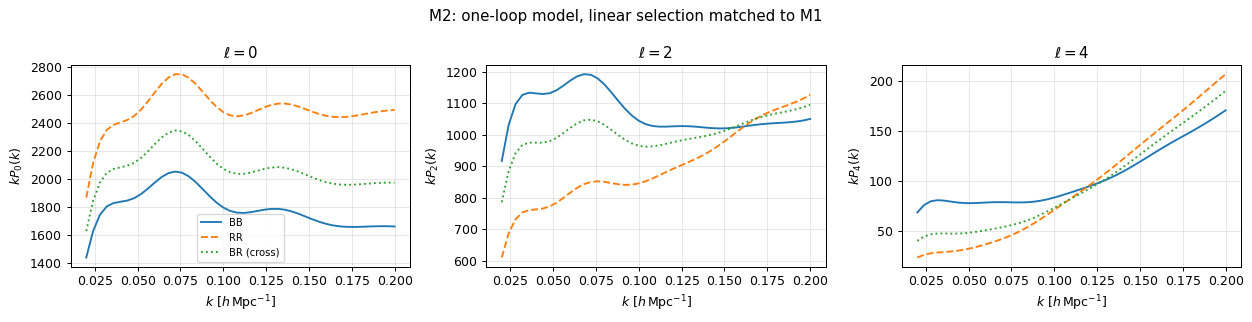

In [7]:
def matched(pars, A):
    """M2 parameters: b1 -> b1 - A/3 and SelectionBias(s_eta=-A/f) (same linear kernel as M1)."""
    b1_djs, s_eta = tree_bA_to_linear_djs(pars[0], A, f0)
    return [b1_djs] + list(pars[1:]), SelectionBias(s_eta=s_eta)

pars_B2, sel_B2 = matched(pars_B, A_B)
pars_R2, sel_R2 = matched(pars_R, A_R)
sel = dict(selection_tables=sel_tables)

P2_BB = calc.get_rsd_pkell(pars=pars_B2, selection=sel_B2, **sel, **common)
P2_RR = calc.get_rsd_pkell(pars=pars_R2, selection=sel_R2, **sel, **common)
P2_BR = calc.get_rsd_pkell(pars=pars_B2, pars_b=pars_R2, cross_nuisance=cross_BR,
                           selection=sel_B2, selection_b=sel_R2, **sel, **common)
print("s_eta (B, R) =", sel_B2.s_eta, sel_R2.s_eta)
plot_spectra({"BB": P2_BB, "RR": P2_RR, "BR (cross)": P2_BR}, "M2: one-loop model, linear selection matched to M1")

## 7. M3: full one-loop selection

All nine coordinates of `SelectionBias` are free and can differ between tracers:
`s_eta` (linear), four quadratic ones (`s_delta_eta, s_eta2, s_KK_par, s_Pi2_par`) and four cubic ones
(`s_delta_Pi2_par, s_eta_Pi2_par, s_KPi2_par, s_Pi3_par`).

Optional terms beyond legacy FolpsD go through `eft_extension=EFTExtension(...)`. For a cross spectrum this is a
pair-level object, e.g. the $k^2\mu^4$ noise `alphashot2_mu4`.

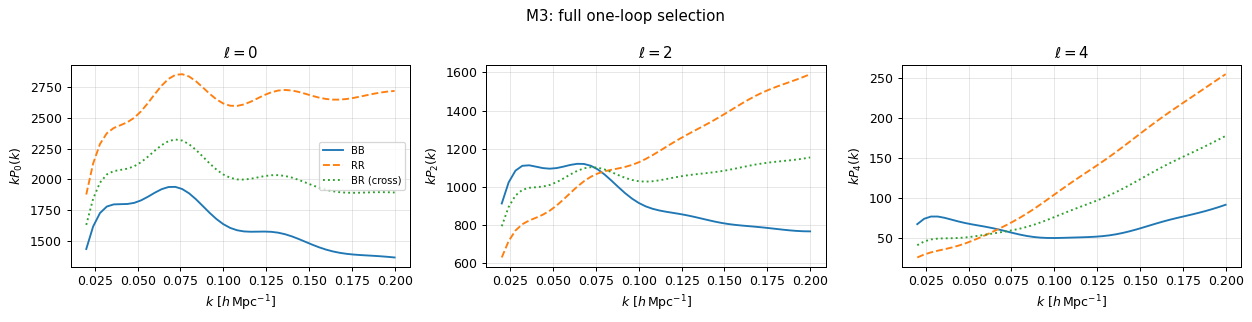

In [8]:
sel_B3 = sel_B2._replace(s_delta_eta=-0.30, s_eta2=0.20, s_KK_par=0.40, s_Pi2_par=-0.50,
                         s_delta_Pi2_par=0.30, s_eta_Pi2_par=-0.20, s_KPi2_par=0.30, s_Pi3_par=0.20)
sel_R3 = sel_R2._replace(s_delta_eta=0.40, s_eta2=-0.20, s_KK_par=-0.30, s_Pi2_par=0.30,
                         s_delta_Pi2_par=-0.10, s_eta_Pi2_par=0.40, s_KPi2_par=-0.30, s_Pi3_par=0.40)
ext = EFTExtension(alphashot2_mu4=-1.0)       # optional; omit for the legacy stochastic basis

P3_BB = calc.get_rsd_pkell(pars=pars_B2, selection=sel_B3, eft_extension=ext, **sel, **common)
P3_RR = calc.get_rsd_pkell(pars=pars_R2, selection=sel_R3, eft_extension=ext, **sel, **common)
P3_BR = calc.get_rsd_pkell(pars=pars_B2, pars_b=pars_R2, cross_nuisance=cross_BR,
                           selection=sel_B3, selection_b=sel_R3, eft_extension=ext, **sel, **common)
plot_spectra({"BB": P3_BB, "RR": P3_RR, "BR (cross)": P3_BR}, "M3: full one-loop selection")

## 8. Comparing the models

The change of each spectrum with respect to M0, relative to the maximum of $|P_\ell^{\rm M0}|$.

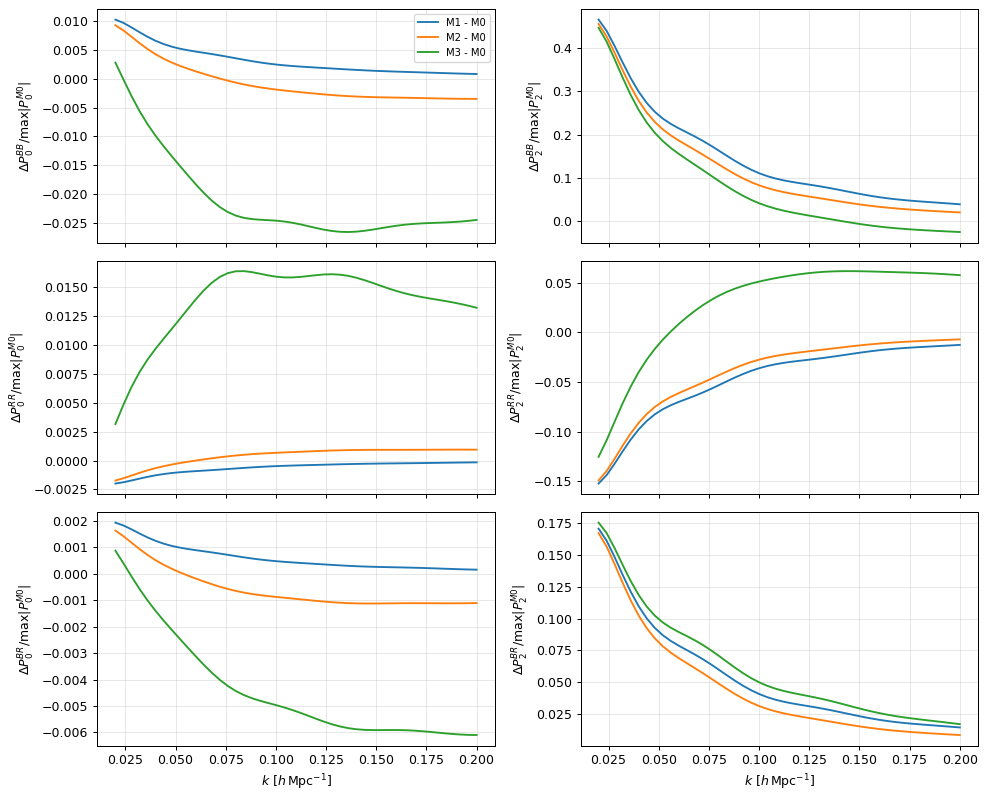

In [9]:
models = {"M1": (P1_BB, P1_RR, P1_BR), "M2": (P2_BB, P2_RR, P2_BR), "M3": (P3_BB, P3_RR, P3_BR)}
ref = (P0_BB, P0_RR, P0_BR)
fig, axs = plt.subplots(3, 2, figsize=(11, 9), sharex=True)
for j, name in enumerate(("BB", "RR", "BR")):
    for i, l in enumerate((0, 2)):
        for m, P in models.items():
            axs[j, i].plot(kobs, (P[j][i] - ref[j][i]) / np.max(np.abs(ref[j][i])), label=f"{m} - M0")
        axs[j, i].set(ylabel=fr"$\Delta P^{{{name}}}_{l} / \max|P^{{M0}}_{l}|$")
axs[0, 0].legend(fontsize=8)
for ax in axs[-1]:
    ax.set_xlabel(r"$k\ [h\,{\rm Mpc}^{-1}]$")
fig.tight_layout(); plt.show()

## 9. Consistency checks

* **Exchange symmetry:** swapping the tracers, including their selections, leaves the cross unchanged.
* **Auto limit:** a cross of a tracer with itself, with `cross_nuisance = pars[4:]`, equals its auto spectrum.
* **Zero selection:** an explicit `SelectionBias()` for both tracers reproduces the unselected (M0) cross.
* **Three autos:** an independent test of the whole cross spectrum. The model is affine in the tracer
  coefficients, so the cross equals $2P(m) - [P(A) + P(B)]/2$. Here $m$ is the midpoint tracer, with averaged
  parameters and selection. This needs `cross_nuisance` equal to the midpoint of the two tracers' nuisance
  entries, and equal `PshotP`.

In [10]:
def rel(a, b):
    return np.max(np.abs(np.asarray(a) - np.asarray(b))) / np.max(np.abs(np.asarray(b)))

checks = {}
P3_RB = calc.get_rsd_pkell(pars=pars_R2, pars_b=pars_B2, cross_nuisance=cross_BR,
                           selection=sel_R3, selection_b=sel_B3, eft_extension=ext, **sel, **common)
checks["exchange symmetry (M3)"] = rel(P3_RB, P3_BR)

P3_BB_cross = calc.get_rsd_pkell(pars=pars_B2, pars_b=pars_B2, cross_nuisance=pars_B2[4:],
                                 selection=sel_B3, selection_b=sel_B3, eft_extension=ext, **sel, **common)
checks["auto limit (M3)"] = rel(P3_BB_cross, P3_BB)

P_zero = calc.get_rsd_pkell(pars=pars_B, pars_b=pars_R, cross_nuisance=cross_BR,
                            selection=SelectionBias(), selection_b=SelectionBias(), **sel, **common)
checks["zero selection = M0 cross"] = rel(P_zero, P0_BR)

mid = lambda x, y: [0.5 * (a + b) for a, b in zip(x, y)]
pars_m, sel_m = mid(pars_B2, pars_R2), SelectionBias(*mid(sel_B3, sel_R3))
auto = lambda p, s: calc.get_rsd_pkell(pars=p, selection=s, eft_extension=ext, **sel, **common)
P_cross_m = calc.get_rsd_pkell(pars=pars_B2, pars_b=pars_R2, cross_nuisance=pars_m[4:],
                               selection=sel_B3, selection_b=sel_R3, eft_extension=ext, **sel, **common)
checks["cross = 2P(mid) - (P(B)+P(R))/2 (M3)"] = rel(P_cross_m, 2 * auto(pars_m, sel_m) - 0.5 * (P3_BB + P3_RR))

for name, value in checks.items():
    print(f"{name:42s} max rel. diff = {value:.1e}")
    assert value < 1e-10, name
print("all checks passed")

exchange symmetry (M3)                     max rel. diff = 1.8e-16
auto limit (M3)                            max rel. diff = 5.1e-17
zero selection = M0 cross                  max rel. diff = 0.0e+00
cross = 2P(mid) - (P(B)+P(R))/2 (M3)       max rel. diff = 5.3e-16
all checks passed


## 10. Notes and limitations

* **Kernels and model:** selection requires EdS kernels and `model="EFT"`, which has no FoG damping and keeps GTNS.
  `fk` tables or `use_GTNS=False` raise an error.
* **Cross nuisance:** a selected cross spectrum needs both `selection` and `selection_b`, plus `cross_nuisance`.
* **Not available for cross spectra:** `physical_derivatives` (the physical derivative counterterm basis) and
  `return_components` raise `NotImplementedError`.
* **Kaiser-only `bA` (M1)** is available through `get_rsd_pkmu` only. It cannot be combined with a nonzero `selection`.
* **Accuracy:** at the default `nfftlog=128`, the mixed two-tracer loops agree with direct numerical integration of the
  kernels to about $10^{-3}$ of the selection increment for $k \le 0.2\,h\,{\rm Mpc}^{-1}$, and to $\sim 10^{-5}$ at
  `nfftlog=256`, when compared with direct numerical integration of the two-tracer kernels.
* **Tests:** `pytest tests/test_selection_cross.py tests/test_selection_cross_audit.py`.